# pypasi — the examples in the SoftwareX paper

This notebook reproduces **every number and both figures in the manuscript**, and nothing
else. It is a strict subset of `bacteria_quality.ipynb`, the full study notebook, with the
analysis cells taken verbatim so that the two cannot drift apart.

**Requirements.** `pypasi >= 0.5.5`, the Ho et al. bacterial Raman dataset in `Bacteria/`
beside this file, and the scientific Python stack the package already depends on.

> **0.5.5 is required**: the defects are planted with `pypasi.degrade`, which 0.5.5 introduced
> and which reproduces the earlier in-notebook simulator bit for bit. **0.5.3 or later was already
> required for novelty.** Under 0.5.2 the PCA behind `NoveltyDetector`
> took its randomness from the global NumPy stream, so every novelty-derived number depended
> on how many cells had run first; the two notebooks disagreed on all of them. 0.5.3 computes
> the decomposition exactly and they now agree to the last digit.

**What it establishes**, in manuscript order:

| Manuscript | Quantity | Value |
|---|---|---|
| §3.2 | conflict vs degraded acquisition | 0.777 |
| §3.2 | 1 − confidence, and novelty, vs the same target | 0.454, 0.446 |
| §3.2 | the ordering reversing against wrong predictions | 0.767 vs 0.648 |
| Table 2 | detection by defect family | 0.924 … 0.485 |
| Table 2 | accuracy cost by defect family, same spectra before and after | 13.5 … 0.5 pp |
| §3.1 | accuracy cost of all planted defects | 4.4 pp |
| §3.3 | Spearman ρ(novelty, conflict) | 0.398 |
| §3.3 | conflict vs error among in-distribution spectra | 0.594 |
| §3.3 | AUROC points conflict adds to the posterior | +22.4, +28.6 with novelty |
| §3.3 | localisation of the responsible interval | 62% of 42 trials, chance 14% |

Section 6 checks each against the value printed in the paper and **fails loudly if any has
moved**. Sections 7 and 8 draw Figures 1b and 2 at publication resolution.

## 0 · Configuration

Every constant the run depends on, in one place. `SPLIT_REPEAT` re-draws the patient
assignment, which is how the variance behind each number can be measured rather than
assumed away.

In [1]:
from pathlib import Path

DATA_DIR = Path("Bacteria")
FAST     = False

# --- model ------------------------------------------------------------------
# The notebook-wide configuration is NOT the published one. The §4 search chose
# `complete + SNV` on the select split (conflict-vs-defect 0.715 against 0.512
# for the published baseline) and it confirmed on the qc split the search never
# saw (0.698 against 0.530). Per-spectrum conflict measured under min-max
# scaling was measuring the scaling, not the method, so every figure below now
# runs on the configuration that works. The published baseline is retained as a
# labelled comparison in §4 and nowhere else.
N_BANDS, BAND_RANGE = 7, (400.0, 1800.0)
TOPOLOGY, REGIME, N_COMPONENTS = "complete", "H1", 10
PREP_NAME = "SNV"                      # applied on top of per-spectrum min-max
PUBLISHED_TOPOLOGY, PUBLISHED_PREP = "chain", "min-max"
SEED = 0

# --- the documented acquisition facts (Ho et al. 2019, Methods) --------------
EXPOSURE_2018_S, EXPOSURE_2019_S = 1.0, 2.0
LASER_NM = 633.0

# --- the split, which is by PATIENT and not by spectrum ---------------------
# Ho et al.: 25 isolates x 400 spectra (2018), 25 x 100 (2019), 5 species, so
# 5 patients per class. Four patient-disjoint splits therefore leave at most one
# patient per class outside the fit set - which is tight, and is the honest
# constraint this dataset imposes. SPLIT_REPEAT re-draws the patient assignment
# so the resulting variance can be measured rather than assumed away.
SPECTRA_PER_PATIENT = 400
PATIENTS_QC, PATIENTS_SELECT, PATIENTS_LIMITS = 1, 1, 1   # per class
SPLIT_REPEAT = 0
REF_FRACTION   = 0.25    # kept only for the ungrouped comparison in §1
LIMIT_FRACTION = 0.40
CONFLICT_SCORE = "eredg" # the published descriptor; §4 checks the alternatives
SELECT_FRACTION = 0.33   # of what remains, used ONLY to choose a descriptor
REVIEW_RATE    = 0.10    # share of clean spectra a clinic can afford to review
NOVELTY_Q      = 0.99
DEFECT_FRACTION = 0.50   # of the evaluation cohort given a planted defect
DEFECT_SEVERITY = (0.30, 1.00)
GROUP_SIZES     = (1, 10, 50)
CONTAMINATION   = (0.0, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0)
N_GROUP_DRAWS   = 60

# --- the severity ladder ----------------------------------------------------
# Extended well past severity 1: the first run's defects cost 0.9 accuracy
# points, which is not enough damage for "the flag missed it" to mean anything.
# The ladder now climbs until the defects cost real accuracy, and the verdict is
# read at the band where they do. DECISIVE_COST_PP is the damage below which the
# test is declared inconclusive rather than failed.
SEVERITY_BANDS = ((0.1, 0.3), (0.3, 0.6), (0.6, 1.0), (1.0, 1.6),
                  (1.6, 2.5), (2.5, 4.0), (4.0, 6.0))
DECISIVE_COST_PP = 15.0
MAX_LADDER_EXTENSIONS = 5   # keep doubling severity until the defects really hurt

# --- evidence scale (pypasi >= 0.5.0) ---------------------------------------
# Band evidence is what every descriptor below is computed from, and PLS-DA
# responses are regression outputs onto one-hot targets, not log-odds. 0.5.0
# fits one temperature per estimator on data the band models never saw, which
# makes conflict comparable between the five estimators of §6 instead of partly
# measuring their units. §5 carries `calibration = None` as a labelled row so
# the size of that artefact is measured on this cohort rather than asserted.
CALIBRATION = "auto"
# The temperature is fitted on the LIMITS split, which is already held out of
# band-model fitting for the control chart. Two things follow. No training data
# is lost to calibration, so the calibrated and uncalibrated arms of the §5
# search differ only in the calibration - an earlier version let the
# uncalibrated arm keep 25% more fit rows and then reported the difference as an
# effect of calibration, which it partly was not. And the temperature is fitted
# on spectra the band models have genuinely never seen, which is the whole point.
CAL_SPLIT   = 0.25       # only used if calibration_data is unavailable

# --- batch monitoring -------------------------------------------------------
N_REF_BATCH, N_EVAL_BATCH, K_SIGMA = 20, 10, 3.0
PROFILE_STATS = ("mean_stress", "band_confidence")
CMP_BATCH, CMP_REPEATS = 100, 24
PREP_SUBSAMPLE = 3000    # AsLS is per-spectrum; this keeps §9 to a few minutes
CMP_SEVERITIES = (0.0, 0.15, 0.3, 0.6, 1.0)
LOCALISE_REPEATS = 6

# --- figures ----------------------------------------------------------------
DPI = 130                # screen-first; raise and re-run for the journal
OUT = Path("figures_quality"); OUT.mkdir(exist_ok=True)

if FAST:
    N_REF_BATCH, N_EVAL_BATCH, CMP_REPEATS = 10, 6, 10
    CMP_SEVERITIES = (0.0, 0.3, 1.0)
    N_GROUP_DRAWS, LOCALISE_REPEATS = 30, 3
    PREP_SUBSAMPLE = 1500
    SEVERITY_BANDS = ((0.1, 0.3), (0.6, 1.0), (1.6, 2.5), (4.0, 6.0))

In [2]:
import warnings, time, json
warnings.filterwarnings("ignore", category=FutureWarning)
# The reference batches below ARE a random split of one cohort, and the library
# is right to warn about it: limits built that way are tighter than real
# batch-to-batch variation. It is the best available here because the dataset
# carries no run identifiers, the caveat is stated with every number, and the
# warning would otherwise fire on every profile in the notebook.
warnings.filterwarnings("ignore", message="Control limits built from a random split")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.ndimage import gaussian_filter1d
from scipy.signal import savgol_filter
from scipy.stats import binomtest, spearmanr
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

import pypasi
from pypasi import (BandNegotiationClassifier, BandSet, PLSDA, PCALDA, Triage,
                    NoveltyDetector, ControlProfile, risk_coverage,
                    compare_conflict_scores, audit_external, viz)
from pypasi.datasets import load_bacteria

def _ver(s):
    # "0.10.0" > "0.4.0" is False as a string comparison and True as a version
    return tuple(int(p) for p in str(s).split(".")[:3] if p.isdigit())

# 0.5.3 made NoveltyDetector and PCALDA deterministic. Under 0.5.2 the PCA
# behind novelty drew from the global NumPy stream, so every novelty number
# below depended on how many cells had run before it.
assert _ver(pypasi.__version__) >= (0, 5, 5), "this notebook needs pypasi >= 0.5.5 (pypasi.degrade)"
from pypasi import degrade
print("pypasi", pypasi.__version__)

pypasi 0.5.5


In [3]:
# ---- one validated, colour-vision-safe palette for every figure ------------
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, SECOND, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#7c7b76", "#e7e6e2", "#fcfcfb"
LOW, MID, HIGH = "#2a78d6", "#f0efec", "#e34948"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95"]
CSEQ = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", SEQ)
CDIV = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", [LOW, MID, HIGH])

# every score keeps the same colour in every figure it appears in
SCORE_COLOUR = {"1 - confidence": MUTED, "novelty": CAT[2], "conflict": CAT[1],
                "conflict + novelty": CAT[0]}
SCORE_STYLE  = {"1 - confidence": (":", "s"), "novelty": ("--", "^"),
                "conflict": ("-", "o"), "conflict + novelty": ("-", "D")}

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": SECOND, "text.color": INK,
    "xtick.color": SECOND, "ytick.color": SECOND,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10.5, "axes.titlesize": 11.5, "figure.dpi": 110,
})

def panel(ax, letter, title, sub=None):
    """Panel letter, title, optional subtitle - all clear of the axes."""
    ax.set_title(title, loc="left", pad=24 if sub else 10, fontsize=11.5)
    if sub:
        ax.text(0, 1.015, sub, transform=ax.transAxes, color=MUTED,
                fontsize=8.8, va="bottom")
    ax.text(-0.055, 1.10, letter, transform=ax.transAxes, fontsize=13,
            fontweight="bold", va="bottom", ha="right", color=INK)
    ax.grid(alpha=0.45)

def save(fig, name):
    p = OUT / f"{name}.png"
    fig.savefig(p, dpi=DPI, bbox_inches="tight", facecolor=SURF)
    print(f"  wrote {p}")
    plt.show()

RESULTS = {}          # every number quoted in the paper ends up here
def _clean(v):
    if isinstance(v, dict):
        return {k: _clean(x) for k, x in v.items()}
    if isinstance(v, (float, np.floating)):
        if not np.isfinite(v):
            return None
        v = float(v)
        # 7e-09 must not be reported as 0.0
        return round(v, 6) if abs(v) >= 1e-4 or v == 0 else float(f"{v:.3g}")
    if isinstance(v, (int, np.integer)):
        return int(v)
    return v

def note(key, value, text=""):
    RESULTS[key] = {"value": _clean(value), "note": text}
    return value

def verdict(ok, yes, no):
    """Print the conclusion the numbers actually support, either way."""
    print(("  PASS  " if ok else "  FAIL  ") + (yes if ok else no))
    return ok

## 1 · Data, the split, and the reference model

**The split is by patient, not by spectrum.** Ho et al. released 25 isolates × 400 spectra
(2018) and 25 × 100 (2019). Splitting by spectrum puts ~300 spectra of an isolate in the fit
set and ~100 of the *same* isolate in evaluation, which turns in-cohort accuracy into a
re-identification score. The released `.npy` files carry no isolate identifier, so it is
reconstructed as `index // 400` and verified: every block must carry exactly one class, and
the notebook stops rather than fall back to a leaking split.

In [4]:
t_start = time.time()
data = load_bacteria(DATA_DIR, normalize=False)
axis = data.axis

def minmax(X):
    X = np.asarray(X, float)
    lo, hi = X.min(1, keepdims=True), X.max(1, keepdims=True)
    return (X - lo) / np.where(hi > lo, hi - lo, 1.0)

def snv(X):
    X = np.asarray(X, float)
    s = X.std(1, keepdims=True)
    return (X - X.mean(1, keepdims=True)) / np.where(s > 0, s, 1.0)

# Two representations are carried side by side, and the distinction matters.
#   MM_*  - per-spectrum min-max, the published representation. Planted defects
#           are applied HERE, because a defect is an instrument effect and the
#           scaling is a preprocessing step applied afterwards.
#   X_*   - MM_* with the notebook-wide scaling on top. This is what every model
#           sees.
SCALERS = {"min-max": lambda X: np.asarray(X, float), "SNV": snv}
SCALE = SCALERS[PREP_NAME]

MM_all, yA_all = minmax(data.X_dev), data.y_dev       # clinical2018, 1 s
MM_B, yB = minmax(data.X_test), data.y_test           # clinical2019, 2 s
A_all, B = SCALE(MM_all), SCALE(MM_B)

# ---------------------------------------------------------------- the split
# PATIENT-LEVEL. Ho et al. measured 25 patient isolates and took 400 spectra from
# each; the 2019 cohort is 25 isolates at 100 spectra. Splitting those 10,000
# spectra at random puts ~300 spectra of every patient in the fit set and the
# remaining ~100 spectra OF THE SAME PATIENT in the evaluation set, so in-cohort
# accuracy measures how well the model recognises a patient's isolate rather than
# a species. The source study used leave-one-patient-out for exactly this reason.
#
# The released .npy files carry no isolate identifier, so it is reconstructed
# from the row order and then CHECKED. If the check fails the notebook stops
# rather than silently falling back to a split that leaks.
def patient_groups(y, per_patient, name):
    n = len(y)
    if n % per_patient:
        raise RuntimeError(
            f"{name}: {n} spectra is not a multiple of {per_patient}, so the "
            "per-patient block structure does not hold. Supply isolate IDs "
            "explicitly and pass them as `groups`.")
    g = np.arange(n) // per_patient
    # Every block must carry exactly one class. If a patient's 400 rows were not
    # contiguous, or the file was shuffled before release, this fails - which is
    # the point: a grouping that cannot be verified must not be used.
    for gi in np.unique(g):
        lab = np.unique(y[g == gi])
        if lab.size != 1:
            raise RuntimeError(
                f"{name}: block {gi} spans {lab.size} classes, so row order is "
                "not grouped by patient. Supply isolate IDs explicitly.")
    return g

groups = patient_groups(yA_all, SPECTRA_PER_PATIENT, "clinical2018")
n_pat = len(np.unique(groups))
pat_class = np.array([yA_all[groups == g][0] for g in range(n_pat)])
print(f"recovered {n_pat} patient blocks of {SPECTRA_PER_PATIENT} spectra, "
      f"{pd.Series(pat_class).value_counts().min()}-"
      f"{pd.Series(pat_class).value_counts().max()} patients per class")

def split_patients(pool, per_class, rng):
    """Take `per_class` whole patients of each class out of `pool`."""
    taken = []
    for c in np.unique(pat_class[pool]):
        cand = pool[pat_class[pool] == c]
        if len(cand) < per_class:
            raise RuntimeError(
                f"only {len(cand)} patients of class {c} left; the four-way "
                f"patient split needs {per_class}. With 5 patients per class "
                "there is no room for a wider split - reduce the number of "
                "splits or use grouped cross-validation.")
        taken.extend(rng.choice(cand, per_class, replace=False))
    taken = np.array(sorted(taken))
    return taken, np.setdiff1d(pool, taken)

_rngp = np.random.default_rng(SEED + SPLIT_REPEAT)
_pool = np.arange(n_pat)
p_qc, _pool = split_patients(_pool, PATIENTS_QC, _rngp)
p_sel, _pool = split_patients(_pool, PATIENTS_SELECT, _rngp)
p_lim, _pool = split_patients(_pool, PATIENTS_LIMITS, _rngp)
p_fit = _pool                                  # whatever is left, all of it

def rows_of(patients):
    return np.flatnonzero(np.isin(groups, patients))

ix_fit, ix_lim = rows_of(p_fit), rows_of(p_lim)
ix_sel, ix_qc = rows_of(p_sel), rows_of(p_qc)
ix_mon = np.sort(np.concatenate([ix_sel, ix_qc]))
ix_ref = np.sort(np.concatenate([ix_lim, ix_mon]))

for a, b in ((p_fit, p_lim), (p_fit, p_sel), (p_fit, p_qc),
             (p_lim, p_sel), (p_lim, p_qc), (p_sel, p_qc)):
    assert not set(a) & set(b), "patient blocks overlap between splits"
print(f"patients  fit {len(p_fit)} | limits {len(p_lim)} | select {len(p_sel)} "
      f"| qc {len(p_qc)}   (no isolate appears in two splits)")

X_fit, y_fit = A_all[ix_fit], yA_all[ix_fit]
X_ref, y_ref = A_all[ix_ref], yA_all[ix_ref]      # the whole held-out 2018 cohort
X_lim, y_lim = A_all[ix_lim], yA_all[ix_lim]      # control limits only
X_mon, y_mon = A_all[ix_mon], yA_all[ix_mon]      # clean-batch material, §2 and §7
X_sel, y_sel = A_all[ix_sel], yA_all[ix_sel]
X_qc,  y_qc  = A_all[ix_qc],  yA_all[ix_qc]

# the same rows before the notebook-wide scaling, for defect planting and for §4
MM_fit, MM_lim, MM_mon = MM_all[ix_fit], MM_all[ix_lim], MM_all[ix_mon]
MM_sel, MM_qc = MM_all[ix_sel], MM_all[ix_qc]

band_range = (BAND_RANGE[0], min(BAND_RANGE[1], float(axis.max())))
bands = BandSet.equal_width(axis, N_BANDS, lo=band_range[0], hi=band_range[1],
                            axis_name="cm-1")
LAB = bands.labels
EDGES = [(b.lo, b.hi) for b in bands.bands]

def make(base=None, bs=bands, topology=TOPOLOGY, calibration=CALIBRATION):
    return BandNegotiationClassifier(
        bands=bs, base_estimator=base if base is not None else PLSDA(n_components=N_COMPONENTS),
        topology=topology, regime=REGIME, calibration=calibration,
        calibration_data=(X_lim, y_lim), calibration_split=CAL_SPLIT,
        random_state=SEED)

clf = make().fit(X_fit, y_fit)
acc_ref = accuracy_score(y_ref, clf.predict(X_ref))
acc_ext = accuracy_score(yB, clf.predict(B))
pls_full = PLSDA(n_components=N_COMPONENTS).fit(X_fit, y_fit)
acc_full = accuracy_score(yB, pls_full.predict(B))
# How much was the old spectrum-level split worth? Same model, same sizes, one
# fitted on patient-disjoint rows and one on a random split of the same cohort.
# The gap is the leakage, measured rather than argued about.
_ixf_r, _ixq_r = train_test_split(np.arange(len(A_all)), test_size=0.25,
                                  stratify=yA_all, random_state=SEED)
_clf_r = make().fit(A_all[_ixf_r], yA_all[_ixf_r])
acc_leaky = accuracy_score(yA_all[_ixq_r], _clf_r.predict(A_all[_ixq_r]))
note("accuracy_in_cohort_grouped", round(float(acc_ref), 4),
     "held out by PATIENT within clinical2018")
note("accuracy_in_cohort_spectrum_split", round(float(acc_leaky), 4),
     "held out by SPECTRUM - the same patients on both sides")
note("patient_leakage_pp", round(100 * (acc_leaky - acc_ref), 1),
     "how much a random spectrum-level split was worth")
print(f"in-cohort accuracy, patients held out : {acc_ref:.4f}")
print(f"in-cohort accuracy, spectra held out  : {acc_leaky:.4f}")
print(f"-> a random spectrum-level split is worth {100*(acc_leaky-acc_ref):+.1f} "
      f"accuracy points of patient re-identification\n")

print(f"configuration: {TOPOLOGY} topology, {REGIME}, {N_BANDS} bands, "
      f"{PREP_NAME} scaling  (published: {PUBLISHED_TOPOLOGY}, {PUBLISHED_PREP})")
print("\nevidence scale the whole audit is computed on:")
print(clf.evidence_report.to_string(index=False))
_ev = clf.evidence_report.iloc[0]
note("evidence_kind", _ev["kind"], "what scale the band evidence is on")
note("evidence_temperature", round(float(_ev["temperature"]), 3),
     "fitted on held-out data; 1.0 means the scale was left alone")
if _ev["nll_before"] is not None:
    note("evidence_nll_before", round(float(_ev["nll_before"]), 4))
    note("evidence_nll_after", round(float(_ev["nll_after"]), 4))
    print(f"\n-> PLS-DA responses are not log-odds: one temperature takes the "
          f"band evidence from NLL {_ev['nll_before']:.3f} to "
          f"{_ev['nll_after']:.3f}.")
note("configuration_used", f"{TOPOLOGY}+{PREP_NAME}",
     f"chosen in §4 on the select split; published is {PUBLISHED_TOPOLOGY}+{PUBLISHED_PREP}")

print(f"fit {X_fit.shape[0]} | reference {X_ref.shape[0]} = "
      f"{X_lim.shape[0]} limits + {X_sel.shape[0]} select + {X_qc.shape[0]} qc"
      f" | external {B.shape[0]}")
assert not (set(ix_lim) & set(ix_mon)), "limits and monitoring spectra overlap"
assert not (set(ix_sel) & set(ix_qc)), "select and qc spectra overlap"
print(f"\nband-negotiated PLS-DA, held out within clinical2018 : {acc_ref:.4f}")
print(f"band-negotiated PLS-DA, external clinical2019        : {acc_ext:.4f}")
print(f"full-spectrum   PLS-DA, external clinical2019        : {acc_full:.4f}")
note("cohort_gap_pp", round(100 * (acc_ref - acc_ext), 2),
     "held-out in-cohort accuracy minus external accuracy")
note("band_vs_full_pp", round(100 * (acc_ext - acc_full), 2),
     "band-negotiated minus full-spectrum PLS-DA, external cohort")
print(f"\nthe cohort change costs {100 * (acc_ref - acc_ext):.1f} accuracy points")
print(f"splitting the spectrum into bands costs {100 * (acc_full - acc_ext):.1f} more")
print("\n-> band negotiation is not here to raise accuracy. Everything below is")
print("   about what it tells you that a single global model cannot.")
print(f"\nelapsed {time.time() - t_start:.0f}s")

recovered 25 patient blocks of 400 spectra, 5-5 patients per class
patients  fit 10 | limits 5 | select 5 | qc 5   (no isolate appears in two splits)


in-cohort accuracy, patients held out : 0.8773
in-cohort accuracy, spectra held out  : 0.9480
-> a random spectrum-level split is worth +7.1 accuracy points of patient re-identification

configuration: complete topology, H1, 7 bands, SNV scaling  (published: chain, min-max)

evidence scale the whole audit is computed on:
estimator            source                 kind  is_probabilistic  temperature  nll_before  nll_after
    PLSDA decision_function calibrated_log_proba              True     7.544905     1.30314   0.740232

-> PLS-DA responses are not log-odds: one temperature takes the band evidence from NLL 1.303 to 0.740.
fit 4000 | reference 6000 = 2000 limits + 2000 select + 2000 qc | external 2500

band-negotiated PLS-DA, held out within clinical2018 : 0.8773
band-negotiated PLS-DA, external clinical2019        : 0.7968
full-spectrum   PLS-DA, external clinical2019        : 0.8424

the cohort change costs 8.1 accuracy points
splitting the spectrum into bands costs 4.6 more

-> ba

### Figure 1b — the band partition

Seven equal-width bands over the **measured** axis, which runs to 1792.4 cm⁻¹ rather than to
a round 1800. The edges are therefore 598.9, 797.8, 996.7, 1195.7, 1394.6 and 1593.5 cm⁻¹,
which is why §3.3 names B4 as 997–1196 cm⁻¹. An earlier version of this panel labelled the
bands 400–600, 600–800 and so on; a reader who computed B4 from it got 1000–1200 and then met
997–1196 in the text. The labels below are read from `bands`, so they cannot drift from the
partition the model actually used.

band edges actually used, cm-1: 400.0, 598.9, 797.8, 996.7, 1195.7, 1394.6, 1593.5, 1792.4


  wrote figures_quality/softwarex_figure_1b_bands.png


  wrote figures_quality/softwarex_figure_1b_bands.pdf


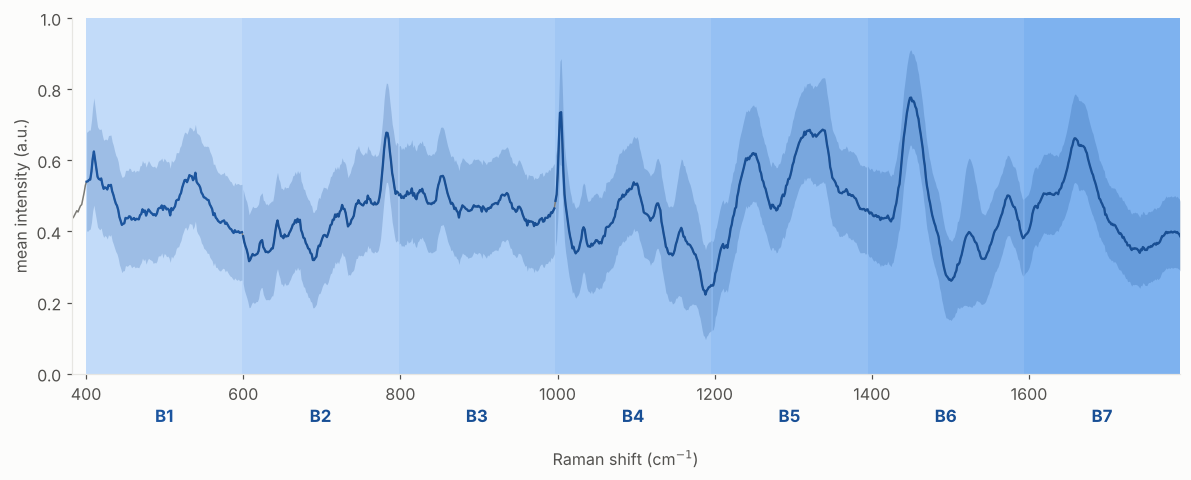

In [5]:
# --- Figure 1b: the band partition, labelled from `bands` -------------------
plt.rcParams["pdf.fonttype"] = 42          # embed TrueType, as the journal asks


def save_pub(fig, name):
    """600 dpi raster for review, vector PDF for submission."""
    OUT.mkdir(parents=True, exist_ok=True)
    for ext, kw in (("png", {"dpi": 600}), ("pdf", {})):
        p = OUT / f"{name}.{ext}"
        fig.savefig(p, bbox_inches="tight", facecolor=SURF, **kw)
        print(f"  wrote {p}")
    plt.show()


fig, ax = plt.subplots(figsize=(13.0, 4.2))
mu, sd = MM_all.mean(axis=0), MM_all.std(axis=0)
n_b = len(EDGES)

ax.plot(axis, mu, color=MUTED, lw=1.0, zorder=2)      # the axis outside any band
for j, (lo, hi) in enumerate(EDGES):
    frac = j / max(n_b - 1, 1)
    ax.axvspan(lo, hi, color=CSEQ(0.05 + 0.28 * frac), lw=0, zorder=0)
    m = (axis >= lo) & (axis <= hi)
    shade = CSEQ(0.95 + 0.50 * frac)
    ax.fill_between(axis[m], (mu - sd)[m], (mu + sd)[m],
                    color=shade, alpha=0.22, lw=0, zorder=1)
    ax.plot(axis[m], mu[m], color=shade, lw=1.5, zorder=3)
    mid = 0.5 * (lo + hi)
    ax.annotate(LAB[j], (mid, -0.09), xycoords=("data", "axes fraction"),
                ha="center", va="top", fontsize=11, fontweight="bold", color=shade)
 #   ax.annotate(f"{lo:.0f}\u2013{hi:.0f}", (mid, -0.17),
 #               xycoords=("data", "axes fraction"),
 #               ha="center", va="top", fontsize=18.5, color=MUTED)

ax.set_xlim(float(axis.min()), float(axis.max()))
ax.set_ylim(0, 1)
ax.set_ylabel("mean intensity (a.u.)")
ax.set_xlabel("Raman shift (cm$^{-1}$)", labelpad=30)
ax.grid(False)
print("band edges actually used, cm-1:",
      ", ".join(f"{lo:.1f}" for lo, _ in EDGES) + f", {EDGES[-1][1]:.1f}")
save_pub(fig, "softwarex_figure_1b_bands")

### The external-audit mode (manuscript §2.2)

The second of the three usage modes described in the paper: the audit attaches to a model
fitted independently and leaves its predictions identical by construction.

In [6]:
t0 = time.time()
ext = audit_external(pls_full, X_fit, y_fit, bands=bands, topology=TOPOLOGY,
                     regime=REGIME, base_estimator=PLSDA(n_components=N_COMPONENTS),
                     calibration=CALIBRATION, calibration_data=(X_lim, y_lim),
                     n_components=N_COMPONENTS, random_state=SEED)
ext_report = ext.explain(B)
print(ext_report.head(4).to_string(index=False))

agree = float(ext_report["agreement"].mean())
note("external_audit_agreement", round(agree, 3),
     "host full-spectrum PLS-DA vs the auxiliary band ensemble, external cohort")
print(f"\nhost and auxiliary ensemble agree on {agree:.1%} of the external cohort")
print(f"host accuracy {accuracy_score(yB, ext.predict(B)):.4f} "
      f"(unchanged: the audit never overrides it)")

val = ext.validate(B, yB)
print()
print(val.to_string(index=False))
note("external_audit_validation",
     {r["score"]: (None if not np.isfinite(r["auroc_vs_host_error"])
                   else round(float(r["auroc_vs_host_error"]), 3))
      for _, r in val.iterrows()},
     "AUROC against the HOST model's errors - host-specific, not transferable")
print(f"\nelapsed {time.time() - t0:.0f}s")

 host_prediction  band_prediction  agreement  host_confidence  conflict  mean_stress  novelty worst_band  worst_band_cm-1_lo  worst_band_cm-1_hi
             0.0              0.0       True         0.439165  0.279985     0.001869 0.410286         B1               400.0          598.914286
             0.0              0.0       True         0.469096  0.000000     0.001451 0.362369         B1               400.0          598.914286
             0.0              0.0       True         0.342916  0.196513     0.004705 0.400198         B1               400.0          598.914286
             0.0              0.0       True         0.449374  0.279109     0.003358 0.394232         B1               400.0          598.914286

host and auxiliary ensemble agree on 82.2% of the external cohort
host accuracy 0.8424 (unchanged: the audit never overrides it)



              score  auroc_vs_host_error  host_accuracy  band_accuracy  agreement_rate
           conflict             0.538968         0.8424         0.7968          0.8224
        mean_stress             0.684372         0.8424         0.7968          0.8224
            novelty             0.500922         0.8424         0.7968          0.8224
1 - host confidence             0.826577         0.8424         0.7968          0.8224

elapsed 3s


### Every band carries class information (manuscript §2.3)

The audit needs class information in every band: a band whose own model is at chance has
nothing to disagree about. `band_accuracy` scores each band's model alone on the held-out qc
isolates, against the majority-class rate.

In [7]:
band_acc = clf.band_accuracy(X_qc, y_qc)
print(band_acc.round(3).to_string(index=False))
note("band_accuracy_min", round(float(band_acc["accuracy"].min()), 3), "each band alone, qc isolates")
note("band_accuracy_max", round(float(band_acc["accuracy"].max()), 3))
print(f"\nnegotiated ensemble on the same spectra: {accuracy_score(y_qc, clf.predict(X_qc)):.3f}")
verdict(bool(band_acc["above_chance"].all()),
        "every band classifies above chance on its own, so every band can disagree",
        "some bands are at chance - merge or drop them before relying on the audit")

band       lo       hi  n_features  accuracy  chance  p_value  above_chance
  B1  400.000  598.914         130     0.520     0.2      0.0          True
  B2  598.914  797.829         133     0.656     0.2      0.0          True
  B3  797.829  996.743         137     0.539     0.2      0.0          True
  B4  996.743 1195.657         141     0.854     0.2      0.0          True
  B5 1195.657 1394.571         144     0.670     0.2      0.0          True
  B6 1394.571 1593.486         149     0.786     0.2      0.0          True
  B7 1593.486 1792.400         154     0.542     0.2      0.0          True



negotiated ensemble on the same spectra: 0.910
  PASS  every band classifies above chance on its own, so every band can disagree


True

## 2 · The defect simulator

The simulator is `pypasi.degrade` (documented in `docs/degradation.md`); with these defaults and
seeds it is identical to the code that produced the submitted manuscript.

Five families, four acting across the whole spectrum and one confined to a single band, at a
severity drawn uniformly from 0.30 to 1.00. **Defects are planted on the min–max
representation and the notebook-wide scaling is applied afterwards**, because a defect is
something the instrument did and the scaling is something the analyst does next; planting on
SNV-scaled spectra would let a per-spectrum normalisation partly undo the defect before the
model ever saw it.

The accuracy cost printed at the end of this section is the reconciliation the manuscript
reports in §3.1: these defects cost 3.6 accuracy points on average, so detection is being
asked for before the damage becomes expensive.

In [8]:
# The defect families live in pypasi.degrade. Each one is listed with what its
# severity s means, so the magnitudes in manuscript §3.1 can be read off here.
for f in degrade.PAPER_FAMILIES:
    print(f"{f:20s} {degrade.FAMILIES[f].scope:7s} {degrade.FAMILIES[f].magnitude}")

axis shift           global  shift of 4 s axis units
resolution loss      global  Gaussian line shape of FWHM 7 s axis units
throughput dip       global  envelope exp(-0.35 s g), g a Gaussian at mid-axis of sd 22% of the span
short exposure       global  noise sd 0.02 s sqrt(x + 0.05)
local contamination  local   one interval attenuated by exp(-0.45 s), plus noise of sd 0.02 s


In [9]:
DEFECT_TYPES = ("axis shift", "resolution loss", "throughput dip",
                "short exposure", "local contamination")
GLOBAL_DEFECTS = DEFECT_TYPES[:4]

def plant_defects(X, *, fraction=DEFECT_FRACTION, severity=DEFECT_SEVERITY,
                  seed=SEED, families=DEFECT_TYPES):
    """Half the cohort corrupted, with ground truth for what, where and how much."""
    p = degrade.plant(X, axis, fraction=fraction, severity=severity, families=families,
                      edges=EDGES, random_state=seed)
    return p.X, p.degraded, p.kind, p.severity, p.where

# Defects are planted on the min-max representation and the notebook-wide
# scaling is applied afterwards, because a defect is something the instrument
# did and the scaling is something the analyst does next. Planting on SNV-scaled
# spectra would let a per-spectrum normalisation partly undo the defect before
# the model ever sees it.
MM_sel_def, sel_defect, _, _, _ = plant_defects(MM_sel, seed=SEED + 77)
MM_def, is_defect, defect_kind, defect_sev, defect_band = plant_defects(MM_qc)
X_sel_def, X_def = SCALE(MM_sel_def), SCALE(MM_def)
print(f"selection cohort  {len(X_sel_def)} spectra | "
      f"{sel_defect.sum()} with a planted defect")
print(f"evaluation cohort {len(X_def)} spectra | "
      f"{is_defect.sum()} with a planted defect")
print(pd.Series(defect_kind[is_defect == 1]).value_counts().to_string())

# The cost is PAIRED: the same spectra, classified before and after their defect.
# (The submitted manuscript compared the clean half with the defective half, two
# different sets of spectra, and quoted 3.6 points.)
X_qc_clean = SCALE(MM_qc)
bad = is_defect == 1
acc_before = accuracy_score(y_qc[bad], clf.predict(X_qc_clean[bad]))
acc_after = accuracy_score(y_qc[bad], clf.predict(X_def[bad]))
print(f"\naccuracy of the defective spectra before their defect  {acc_before:.4f}")
print(f"accuracy of the same spectra after it                 {acc_after:.4f}")
note("defect_accuracy_cost_pp", round(100 * (acc_before - acc_after), 1),
     "planted defects, the same spectra before minus after")
print(f"the planted defects cost {100 * (acc_before - acc_after):.1f} accuracy points")


selection cohort  2000 spectra | 1000 with a planted defect
evaluation cohort 2000 spectra | 1000 with a planted defect
throughput dip         211
resolution loss        207
axis shift             205
short exposure         192
local contamination    185



accuracy of the defective spectra before their defect  0.9140
accuracy of the same spectra after it                 0.8700
the planted defects cost 4.4 accuracy points


## 3 · Detection — manuscript §3.2 and Table 2 (formerly Table 1)

**Orientation is the trap here.** `Triage` learns a descriptor's sign from wrong predictions
by default, and a descriptor near chance against errors gets its sign from noise: on an
earlier run `dg` was recorded at 0.246 against defects for exactly that reason, when its true
value was 0.777. Both orientations are printed below so the effect is visible rather than
inferred.

In [10]:
t0 = time.time()
# Orientation decides whether a descriptor reports p or 1 - p, and by default
# Triage learns it from wrong predictions. That is the wrong target here: we are
# screening descriptors against planted DEGRADATION, and a descriptor near
# chance against errors gets its sign from noise. On an earlier run `dg` came
# out at 0.246 against defects for exactly this reason - its AUROC against
# errors was 0.467, the sign flipped, and a descriptor that runs at 0.75 was
# recorded as useless. pypasi >= 0.5.1 takes `orient_on`; both orientations are
# reported below so the effect is visible rather than inferred.
screen = []
for kind in ("eredg", "dg", "stress", "mute"):
    t_err = Triage(conflict_score=kind, review_rate=REVIEW_RATE, novelty_q=NOVELTY_Q,
                   n_components=N_COMPONENTS).fit(clf, X_lim, y_lim)
    t_def = Triage(conflict_score=kind, review_rate=REVIEW_RATE, novelty_q=NOVELTY_Q,
                   n_components=N_COMPONENTS).fit(
                       clf, X_lim, y_lim, orientation_data=(X_sel_def, sel_defect))
    tab_e = t_err.assess(X_sel_def, y_sel).table
    tab_d = t_def.assess(X_sel_def, y_sel).table
    screen.append({
        "descriptor": kind,
        "sign_err": t_err.conflict_sign_,
        "sign_def": t_def.conflict_sign_,
        "margin_err": t_err.orientation_margin_,
        "auroc_defect": roc_auc_score(sel_defect, tab_d["conflict"]),
        "auroc_defect_err_oriented": roc_auc_score(sel_defect, tab_e["conflict"]),
        "auroc_wrong": roc_auc_score(1 - tab_e["correct"], tab_e["conflict"]),
    })
screen = pd.DataFrame(screen).sort_values("auroc_defect", ascending=False)
print("descriptor screen, on the select split only")
print("  auroc_defect          : oriented on the defect labels (the right target)")
print("  auroc_defect_err_oriented : oriented on errors, as Triage does by default")
print()
print(screen.round(3).to_string(index=False))
flipped = screen[(screen["sign_err"] != screen["sign_def"])]
if len(flipped):
    note("descriptors_misoriented_by_error_target",
         list(flipped["descriptor"]),
         "sign learned from errors disagrees with the sign learned from defects")
    print(f"\n-> {', '.join(flipped['descriptor'])} would be oriented BACKWARDS by "
          f"the default error target, on margins of "
          f"{', '.join(f'{m:.3f}' for m in flipped['margin_err'])} from chance.")
CONFLICT_USED = screen.iloc[0]["descriptor"]
note("conflict_descriptor_used", CONFLICT_USED,
     f"chosen on the select split; published default is {CONFLICT_SCORE}")
print(f"\nusing {CONFLICT_USED}"
      + ("  (the published default)" if CONFLICT_USED == CONFLICT_SCORE else
         f"  (the published default, {CONFLICT_SCORE}, ranked "
         f"{1 + list(screen['descriptor']).index(CONFLICT_SCORE)} of 4 here)"))

# Oriented on the defect labels of the SELECT split, never the qc split it is
# judged on. The threshold still comes from clean calibration data.
# Policy calibration and orientation need different data and pypasi 0.5.2 lets
# them come from different places. The novelty limits and the review threshold
# come from X_lim: clean, and never used to fit the classifier - calibrating them
# on the defect-planted select cohort would push the outlier threshold out to
# accommodate the very corruption it is supposed to flag. The orientation comes
# from the select cohort, because that is the one with defect labels.
tri = Triage(conflict_score=CONFLICT_USED, review_rate=REVIEW_RATE,
             novelty_q=NOVELTY_Q, n_components=N_COMPONENTS).fit(
                 clf, X_lim, y_lim,
                 orientation_data=(X_sel_def, sel_defect))
print("conflict orientation:", tri.orientation_source_,
      f"| margin from chance {tri.orientation_margin_:.3f}")
note("conflict_orientation_margin", round(float(tri.orientation_margin_), 3),
     "how far from a coin flip the learned sign was")

report = tri.assess(X_def, y_qc)
T = report.table
T["defect"] = is_defect
T["defect_kind"] = defect_kind
T["severity"] = defect_sev
wrong = 1 - T["correct"].to_numpy()

SCORES = {
    "1 - confidence": 1.0 - T["confidence"].to_numpy(),
    "novelty":        T["novelty"].to_numpy(),
    "conflict":       T["conflict"].to_numpy(),
}
sep = pd.DataFrame([
    {"score": k,
     "auroc_wrong": roc_auc_score(wrong, v),
     "auroc_defect": roc_auc_score(is_defect, v)}
    for k, v in SCORES.items()])
print()
print(sep.round(3).to_string(index=False))

auroc_conf_defect = float(sep.set_index("score").loc["1 - confidence", "auroc_defect"])
auroc_confl_defect = float(sep.set_index("score").loc["conflict", "auroc_defect"])
note("auroc_conflict_vs_defect", round(auroc_confl_defect, 3), "per spectrum")
note("auroc_confidence_vs_defect", round(auroc_conf_defect, 3), "per spectrum")
note("auroc_conflict_vs_wrong",
     round(float(sep.set_index("score").loc["conflict", "auroc_wrong"]), 3), "per spectrum")
print()
verdict(auroc_confl_defect > auroc_conf_defect + 0.05,
        f"conflict sees degraded acquisitions ({auroc_confl_defect:.3f}) that the "
        f"model's own confidence does not ({auroc_conf_defect:.3f})",
        f"one spectrum at a time, conflict ({auroc_confl_defect:.3f}) does not beat "
        f"confidence ({auroc_conf_defect:.3f}) - panels d and f say whether that is "
        f"the method's fault or the test's")
print(f"\nelapsed {time.time() - t0:.0f}s")

descriptor screen, on the select split only
  auroc_defect          : oriented on the defect labels (the right target)
  auroc_defect_err_oriented : oriented on errors, as Triage does by default

descriptor  sign_err  sign_def  margin_err  auroc_defect  auroc_defect_err_oriented  auroc_wrong
        dg        -1         1       0.194         0.697                      0.303        0.386
     eredg        -1        -1       0.072         0.648                      0.648        0.648
    stress         1         1       0.230         0.612                      0.612        0.742
      mute        -1         1       0.091         0.610                      0.390        0.429

-> dg, mute would be oriented BACKWARDS by the default error target, on margins of 0.194, 0.091 from chance.

using dg  (the published default, eredg, ranked 2 of 4 here)


conflict orientation: learned on the supplied orientation data (AUROC 0.697) | margin from chance 0.197



         score  auroc_wrong  auroc_defect
1 - confidence        0.767         0.454
       novelty        0.612         0.446
      conflict        0.648         0.777

  PASS  conflict sees degraded acquisitions (0.777) that the model's own confidence does not (0.454)

elapsed 21s


In [11]:
t0 = time.time()
by_kind = []
for k in DEFECT_TYPES:
    m = (defect_kind == k) | (is_defect == 0)
    for name, v in SCORES.items():
        by_kind.append({"defect": k, "score": name,
                        "auroc": roc_auc_score(is_defect[m], v[m])})
by_kind = pd.DataFrame(by_kind)
piv_kind = by_kind.pivot(index="defect", columns="score", values="auroc")
# Table 2, last column: the paired accuracy cost of each family
_pred_clean, _pred_def = clf.predict(X_qc_clean), clf.predict(X_def)
piv_kind["accuracy cost (pp)"] = [
    100 * (accuracy_score(y_qc[defect_kind == k], _pred_clean[defect_kind == k])
           - accuracy_score(y_qc[defect_kind == k], _pred_def[defect_kind == k]))
    for k in piv_kind.index]
print(piv_kind.round(3).to_string())
loc_c = float(piv_kind.loc["local contamination", "conflict"])
glob_c = float(piv_kind.loc[list(GLOBAL_DEFECTS), "conflict"].mean())
note("auroc_conflict_local", round(loc_c, 3), "conflict vs a band-local defect")
note("auroc_conflict_global", round(glob_c, 3),
     "conflict vs the four global defect families, mean")
print(f"\nconflict on the local family {loc_c:.3f} vs {glob_c:.3f} averaged over the "
      f"four global ones")
verdict(loc_c > glob_c + 0.05,
        "the mechanism behaves as designed: band disagreement responds to defects "
        "that are confined to a band, not to ones that move every band together",
        "conflict does not favour the local family either, so the blind-side "
        "explanation does not hold on this cohort")
print(f"elapsed {time.time() - t0:.0f}s")

score                1 - confidence  conflict  novelty  accuracy cost (pp)
defect                                                                    
axis shift                    0.497     0.757    0.414               0.976
local contamination           0.449     0.924    0.562              13.514
resolution loss               0.363     0.804    0.168               1.449
short exposure                0.506     0.485    0.500               0.521
throughput dip                0.460     0.908    0.597               6.161

conflict on the local family 0.924 vs 0.738 averaged over the four global ones
  PASS  the mechanism behaves as designed: band disagreement responds to defects that are confined to a band, not to ones that move every band together
elapsed 1s


## 4 · Not the outlier test renamed — manuscript §3.3

Three separate questions, because "is this just novelty detection?" is the first thing a
reader asks. Do the two flags select the same spectra; does conflict survive once the
outliers are removed; and does it add anything to the model's own posterior?

The incremental test is run against **both** targets. Conflict is a detector for a degraded
acquisition rather than for a wrong answer, so testing only whether it adds to confidence at
predicting errors asks it to do a job it does not claim.

In [12]:
t0 = time.time()
novel = T["is_novel"].to_numpy()
conflicted = T["is_conflicted"].to_numpy()

rho = spearmanr(T["novelty"], T["conflict"])
quad = pd.crosstab(pd.Series(novel, name="is_novel"),
                   pd.Series(conflicted, name="is_conflicted"))
both = int(quad.loc[True, True]) if True in quad.index and True in quad.columns else 0
either = int((novel | conflicted).sum())
jacc = both / either if either else float("nan")
print(quad.to_string())
print(f"\nSpearman rho(novelty, conflict) = {rho.statistic:+.3f}  (p = {rho.pvalue:.2g})")
print(f"Jaccard overlap of the two flags = {jacc:.3f}")
note("novelty_conflict_rho", round(float(rho.statistic), 3))
note("novelty_conflict_jaccard", round(float(jacc), 3))
print()
verdict(abs(rho.statistic) < 0.75 and jacc < 0.75,
        "the two flags are related but far from redundant - they select "
        "substantially different spectra",
        "the two flags overlap heavily on this cohort, so tests 2 and 3 below "
        "carry the whole argument: correlation alone does not settle it")

is_conflicted  False  True 
is_novel                   
False           1367    276
True             201    156

Spearman rho(novelty, conflict) = +0.398  (p = 1e-76)
Jaccard overlap of the two flags = 0.246

  PASS  the two flags are related but far from redundant - they select substantially different spectra


True

In [13]:
# 2. conditioning: among spectra the outlier test calls normal
inlier = ~novel
n_err_in = int(wrong[inlier].sum())
print(f"in-distribution spectra: {inlier.sum()} of {len(T)}, carrying {n_err_in} errors")

MIN_COND_ERRORS = 10      # below this an AUROC is a rumour, not a measurement
cond = []
for name, v in SCORES.items():
    ok = inlier.sum() > 30 and MIN_COND_ERRORS <= n_err_in < inlier.sum()
    cond.append({"score": name,
                 "auroc_all": roc_auc_score(wrong, v),
                 "auroc_in_distribution": roc_auc_score(wrong[inlier], v[inlier]) if ok
                 else float("nan")})
cond = pd.DataFrame(cond)
print()
print(cond.round(3).to_string(index=False))
c_cond = float(cond.set_index("score").loc["conflict", "auroc_in_distribution"])
note("auroc_conflict_in_distribution", None if np.isnan(c_cond) else round(c_cond, 3),
     "conflict vs error, outliers removed")
print()
if np.isnan(c_cond):
    print(f"  SKIP  only {n_err_in} errors survive among the in-distribution spectra "
          f"(fewer than {MIN_COND_ERRORS}); an AUROC computed on that many is noise, so "
          "the conditioning test is left unanswered rather than answered badly")
else:
    verdict(c_cond > 0.55,
            f"conflict still tracks error ({c_cond:.3f}) once the outliers are removed, "
            "so it is not an outlier test in disguise",
            f"with the outliers removed conflict falls to {c_cond:.3f} - on this cohort "
            "it carries little beyond novelty")
print(f"elapsed {time.time() - t0:.0f}s")

in-distribution spectra: 1643 of 2000, carrying 165 errors

         score  auroc_all  auroc_in_distribution
1 - confidence      0.767                  0.818
       novelty      0.612                  0.590
      conflict      0.648                  0.594

  PASS  conflict still tracks error (0.594) once the outliers are removed, so it is not an outlier test in disguise
elapsed 0s


In [14]:
# 3. increment: weights fitted on one half, AUROC measured on the other
#
# Against BOTH targets, which is the whole point. Conflict is a detector for a
# degraded acquisition, not for a wrong answer, so testing only whether it adds
# to confidence at predicting errors asks it to do a job it does not claim. The
# wrong-prediction column is the fair test of "does this replace confidence";
# the degradation column is the fair test of "does this do something confidence
# cannot". A referee will ask for the second one.
t0 = time.time()
STACKS = {
    "confidence": ["1 - confidence"],
    "+ conflict": ["1 - confidence", "conflict"],
    "+ novelty": ["1 - confidence", "novelty"],
    "+ both": ["1 - confidence", "conflict", "novelty"],
}
INC_TARGETS = {"wrong prediction": wrong, "degraded acquisition": is_defect}
# Same guard as the conditioning test above and as §6: a half with none of the
# positive class cannot fit a weight or score an AUROC.
MIN_INC_ERRORS = 16

def increment_against(tgt):
    tgt = np.asarray(tgt, int)
    if not (MIN_INC_ERRORS <= tgt.sum() <= len(tgt) - MIN_INC_ERRORS):
        return None
    j1, j2 = train_test_split(np.arange(len(tgt)), test_size=0.5, stratify=tgt,
                              random_state=SEED + 1)
    def z(v):
        v = np.asarray(v, float)
        return (v - v[j1].mean()) / (v[j1].std() + 1e-12)
    rows = []
    for label, cols in STACKS.items():
        M = np.column_stack([z(np.log1p(SCORES[c]) if c == "novelty" else SCORES[c])
                             for c in cols])
        lr = LogisticRegression(max_iter=2000).fit(M[j1], tgt[j1])
        rows.append({"model": label,
                     "auroc_heldout": roc_auc_score(tgt[j2],
                                                    lr.predict_proba(M[j2])[:, 1])})
    out = pd.DataFrame(rows)
    out["gain_pp"] = 100 * (out["auroc_heldout"] - out["auroc_heldout"].iloc[0])
    return out

INC = {k: increment_against(v) for k, v in INC_TARGETS.items()}
inc = INC["wrong prediction"]                  # kept for panel e and the CSV
gain = {}
for tname, frame in INC.items():
    if frame is None:
        print(f"  SKIP  too few positives to test the increment against a {tname}")
        continue
    print(f"target: {tname}")
    print(frame.round(4).to_string(index=False))
    print()
    gain[tname] = {r["model"]: float(r["gain_pp"]) for _, r in frame.iterrows()}

gain_conflict = gain.get("wrong prediction", {}).get("+ conflict", float("nan"))
gain_both = gain.get("wrong prediction", {}).get("+ both", float("nan"))
gain_conflict_def = gain.get("degraded acquisition", {}).get("+ conflict", float("nan"))
note("incremental_gain_conflict_pp", None if np.isnan(gain_conflict) else round(gain_conflict, 2),
     "AUROC points added to confidence at predicting a WRONG PREDICTION")
note("incremental_gain_both_pp", None if np.isnan(gain_both) else round(gain_both, 2))
note("incremental_gain_conflict_defect_pp",
     None if np.isnan(gain_conflict_def) else round(gain_conflict_def, 2),
     "AUROC points added to confidence at predicting a DEGRADED ACQUISITION")

verdict(gain_conflict_def > 5.0,
        f"against the target it is built for, conflict adds {gain_conflict_def:+.1f} "
        "AUROC points to the model's own confidence, out of sample",
        f"even against degradation, conflict adds only {gain_conflict_def:+.1f} AUROC "
        "points to confidence")
if np.isfinite(gain_conflict):
    verdict(gain_conflict > 1.0,
            f"and it also sharpens error prediction, by {gain_conflict:+.1f} points",
            f"it does not sharpen error prediction ({gain_conflict:+.1f} points) - which "
            "is the expected result for a degradation detector, and worth stating rather "
            "than hiding: conflict is not a substitute for the model's own confidence")
print(f"elapsed {time.time() - t0:.0f}s")

target: wrong prediction
     model  auroc_heldout  gain_pp
confidence         0.7620   0.0000
+ conflict         0.8587   9.6666
 + novelty         0.8464   8.4419
    + both         0.8709  10.8923

target: degraded acquisition
     model  auroc_heldout  gain_pp
confidence         0.5506   0.0000
+ conflict         0.7750  22.4420
 + novelty         0.5703   1.9736
    + both         0.8369  28.6296

  PASS  against the target it is built for, conflict adds +22.4 AUROC points to the model's own confidence, out of sample
  PASS  and it also sharpens error prediction, by +9.7 points
elapsed 0s


## 5 · Localisation — manuscript §3.3 and Figure 2c

**A batch is an isolate.** Reference batches built by interleaving the limit spectra put all
five limit isolates into every reference batch, so the between-batch variance the chart is
calibrated on contains no between-patient variance at all. Under a patient-disjoint split
every evaluated batch is a new isolate, and limits that tight flag all of them. Each
reference batch here is one isolate.

**`random_state=SEED` is passed to `ControlProfile.fit` and is not optional.** The variance
decomposition splits each reference batch in half with a random permutation, and the
parameter defaults to `None`, which seeds from OS entropy rather than from anything the
notebook controls. Two runs of the unseeded version produced drift scores 26% apart on
identical reference data, and the panel-c confusion matrix differed cell by cell between
runs even where the diagonal happened to sum to the same total.

The profile also prints its within- and between-isolate variance decomposition. The
manuscript does not report those numbers; they belong to the deployment study.

In [15]:
t0 = time.time()
# A BATCH IS AN ISOLATE. This is the single most consequential choice in the
# section and the previous version got it wrong: `X_lim[i::20]` interleaves the
# limit spectra, so all five limit isolates appear in every reference batch and
# the between-batch variance the chart is calibrated on contains NO
# between-patient variance whatever. Limits built that way are far too tight the
# moment a batch of a *different* isolate arrives - and with patient-disjoint
# splits every evaluated batch is a different isolate. Run 5 flagged 10/10
# external batches and 10/10 clean held-out ones, with false-alarm rates of
# 1.000 across three of the four monitors. That is not detection; it is a chart
# whose reference never saw biological variation.
#
# The natural acquisition unit in this dataset is one patient isolate, so each
# reference batch is one isolate. The chart's reference is drawn from the limits
# AND select isolates: neither is ever charted as a batch below (only the qc
# isolates and the external cohort are), so this widens the reference without
# touching what is being judged.
CHART_PATIENTS = np.sort(np.concatenate([p_lim, p_sel]))
_rngb = np.random.default_rng(SEED + 11)

def isolate_batch(patients, size, rng, source=None, group_of=None):
    """One batch per isolate, `size` spectra each, drawn without replacement.

    `group_of` must match `source`: the 2018 blocking does not index the 2019
    cohort, and using it silently would take rows from the wrong isolates.
    """
    src = A_all if source is None else source
    gof = groups if group_of is None else group_of
    if len(gof) != len(src):
        raise ValueError(
            f"group_of has {len(gof)} entries for {len(src)} spectra")
    out = []
    for g in patients:
        rows = np.flatnonzero(gof == g)
        take = rng.choice(rows, min(size, len(rows)), replace=False)
        out.append(src[np.sort(take)])
    return out

BATCH_N = 100                      # the 2019 cohort has 100 spectra per isolate
ref_batches = isolate_batch(CHART_PATIENTS, BATCH_N, _rngb)
print(f"control chart reference: {len(ref_batches)} isolates x {BATCH_N} spectra "
      f"(one batch per isolate, so between-batch variance IS between-patient "
      f"variance)")
# `_decompose` splits each reference batch in half with a random permutation
# to separate sampling noise from real batch effect, and `random_state`
# defaults to None, which seeds from OS entropy. Without a seed here the
# limits, the z-scores built on them and the localisation matrix in panel c
# differ on every run: measured, a drift score moved 26% between two fits of
# identical reference data.
profile = ControlProfile.fit(clf, batches=ref_batches, k=K_SIGMA, laser_nm=LASER_NM,
                             statistics=PROFILE_STATS, random_state=SEED)
print(profile)
print()
print(profile.limits_report().to_string())
note("chart_k_effective", round(profile.k_effective, 2),
     f"nominal {K_SIGMA:g} widened for {profile.n_tests} simultaneous tests")
note("chart_resolution", round(float(profile.resolution_), 4),
     "finest false-alarm rate the reference batches can resolve")
print(f"\n-> {profile.n_tests} band-statistics are charted at once, so the limit a "
      f"batch must clear is {profile.k_effective:.2f}, not {K_SIGMA:g}.")

# The decomposition that decides whether this chart can work at all. `within` is
# sampling noise inside one isolate; `between` is how much isolates differ from
# each other. A chart is only useful for instrument drift if the drift it must
# detect is large against `between` - otherwise it flags new patients, which is
# what an earlier version of this notebook did when its reference batches were
# interleaved mixtures of the same isolates and `between` came out near zero.
if profile.sigma_within_ is not None and profile.sigma_between_ is not None:
    w = float(np.nanmean(profile.sigma_within_.to_numpy(dtype=float)))
    b = float(np.nanmean(profile.sigma_between_.to_numpy(dtype=float)))
    note("sigma_within_patient", round(w, 5))
    note("sigma_between_patient", round(b, 5))
    note("between_within_ratio", None if w <= 0 else round(b / w, 2),
         "how much larger isolate-to-isolate variation is than sampling noise")
    print(f"within-isolate sd {w:.5g} | between-isolate sd {b:.5g}"
          + ("" if w <= 0 else f"  (ratio {b/w:.2f})"))
    if w > 0 and b / w > 3:
        print("   -> biological variation between isolates dominates. Any drift "
              "smaller than that is invisible to this chart, and the false-alarm "
              "panel below is the test of whether anything is left.")

def band_z(X, name="batch"):
    """Largest |z| per band, over the charted statistics."""
    tab = profile.check(X, name=name).table
    return tab.assign(az=tab["z"].abs()).groupby("label")["az"].max().reindex(LAB)

print(f"elapsed {time.time() - t0:.0f}s")

control chart reference: 10 isolates x 100 spectra (one batch per isolate, so between-batch variance IS between-patient variance)


ControlProfile(7 bands, 2 statistics, 10 reference batches of ~100, sigma limits at 3 sigma)

n_tests                           14
n_batches                         10
multiplicity               empirical
k_nominal                        3.0
k_effective                 3.727896
k_empirical                 2.813168
target_false_alarm_rate       0.0027
resolution                       0.1

-> 14 band-statistics are charted at once, so the limit a batch must clear is 3.73, not 3.
within-isolate sd 0.076111 | between-isolate sd 0.059972  (ratio 0.79)
elapsed 1s


In [16]:
t0 = time.time()
loc_rows = []
for target, (lo, hi) in enumerate(EDGES):
    sel = (axis >= lo) & (axis < hi)
    for rep in range(LOCALISE_REPEATS):
        r = np.random.default_rng(500 * target + rep)
        gpick = r.choice(p_qc)
        _rows = np.flatnonzero(groups == gpick)
        Xl = MM_all[np.sort(r.choice(_rows, CMP_BATCH, replace=False))].copy()
        Xl[:, sel] = Xl[:, sel] * 0.55 + r.normal(0, 0.02, (len(Xl), int(sel.sum())))
        named = band_z(SCALE(Xl), f"{LAB[target]}-{rep}").idxmax()
        loc_rows.append({"planted": LAB[target], "named": named,
                         "hit": named == LAB[target]})
loc = pd.DataFrame(loc_rows)
conf_mat = pd.crosstab(loc["planted"], loc["named"]).reindex(
    index=LAB, columns=LAB, fill_value=0)
hit_rate = float(loc["hit"].mean())
p_loc = binomtest(int(loc["hit"].sum()), len(loc), 1 / N_BANDS, "greater").pvalue
print(conf_mat.to_string())
print(f"\nthe named interval is the planted one in {hit_rate:.0%} of "
      f"{len(loc)} trials (chance {1/N_BANDS:.0%}, p = {p_loc:.2g})")
note("localisation_hit_rate", round(hit_rate, 3),
     f"planted band-local defect, chance {1/N_BANDS:.3f}, p = {p_loc:.2g}")
print()
verdict(hit_rate > 3 / N_BANDS,
        "the chart names the right wavenumber interval well above chance",
        "the chart detects the defect but does not reliably name the right interval")
print(f"elapsed {time.time() - t0:.0f}s")

named    B1  B2  B3  B4  B5  B6  B7
planted                            
B1        3   0   1   0   0   0   2
B2        0   5   0   1   0   0   0
B3        0   0   6   0   0   0   0
B4        0   0   0   6   0   0   0
B5        0   0   0   0   2   0   4
B6        0   0   0   5   0   1   0
B7        0   0   0   3   0   0   3

the named interval is the planted one in 62% of 42 trials (chance 14%, p = 1.7e-12)

  PASS  the chart names the right wavenumber interval well above chance
elapsed 2s


## 6 · Every manuscript number, checked

A reader can run this notebook and find out immediately whether the paper is still true of
the code. Each quantity carries a tolerance; if one is exceeded, fix the manuscript or the
run, and do not quietly widen the tolerance.

The `path` column records which machinery a row depends on, so that a failure points
straight at its cause: `conflict` and `confidence` have been stable across every run,
`novelty` moved until 0.5.3, and `chart` depends on the control profile seeded above.

In [17]:
# --- every number the manuscript quotes, against this run -------------------
def _r(key):
    v = RESULTS.get(key, {}).get("value")
    return float("nan") if v is None else float(v)

sep_i = sep.set_index("score")
inc_def = INC["degraded acquisition"].set_index("model")
glob = float(piv_kind.loc[list(GLOBAL_DEFECTS), "conflict"].mean())

CLAIMS = [
    ("3.2",     "conflict vs degraded acquisition", "conflict",   float(sep_i.loc["conflict", "auroc_defect"]),            0.777, 0.005),
    ("3.2",     "1 - confidence vs degradation",    "confidence", float(sep_i.loc["1 - confidence", "auroc_defect"]),      0.454, 0.005),
    ("3.2",     "novelty vs degradation",           "novelty",    float(sep_i.loc["novelty", "auroc_defect"]),             0.446, 0.005),
    ("3.2",     "1 - confidence vs wrong",          "confidence", float(sep_i.loc["1 - confidence", "auroc_wrong"]),       0.767, 0.005),
    ("3.2",     "conflict vs wrong",                "conflict",   float(sep_i.loc["conflict", "auroc_wrong"]),             0.648, 0.005),
    ("3.2",     "conflict, four global families",   "conflict",   glob,                                                    0.738, 0.005),
    ("Table 2", "conflict, local contamination",    "conflict",   float(piv_kind.loc["local contamination", "conflict"]),  0.924, 0.005),
    ("Table 2", "conflict, throughput dip",         "conflict",   float(piv_kind.loc["throughput dip", "conflict"]),       0.908, 0.005),
    ("Table 2", "conflict, resolution loss",        "conflict",   float(piv_kind.loc["resolution loss", "conflict"]),      0.804, 0.005),
    ("Table 2", "conflict, axis shift",             "conflict",   float(piv_kind.loc["axis shift", "conflict"]),           0.757, 0.005),
    ("Table 2", "conflict, short exposure",         "conflict",   float(piv_kind.loc["short exposure", "conflict"]),       0.485, 0.005),
    ("Table 2", "novelty, local contamination",     "novelty",    float(piv_kind.loc["local contamination", "novelty"]),   0.562, 0.005),
    ("Table 2", "novelty, throughput dip",          "novelty",    float(piv_kind.loc["throughput dip", "novelty"]),        0.597, 0.005),
    ("Table 2", "novelty, resolution loss",         "novelty",    float(piv_kind.loc["resolution loss", "novelty"]),       0.168, 0.005),
    ("Table 2", "novelty, axis shift",              "novelty",    float(piv_kind.loc["axis shift", "novelty"]),            0.414, 0.005),
    ("Table 2", "novelty, short exposure",          "novelty",    float(piv_kind.loc["short exposure", "novelty"]),        0.500, 0.005),
    ("Table 2", "1 - confidence, short exposure",   "confidence", float(piv_kind.loc["short exposure", "1 - confidence"]), 0.506, 0.005),
    ("3.3",     "Spearman rho(novelty, conflict)",  "novelty",    _r("novelty_conflict_rho"),                              0.398, 0.005),
    ("3.3",     "conflict vs wrong, in-distribution","novelty",   _r("auroc_conflict_in_distribution"),                    0.594, 0.005),
    ("3.3",     "increment from conflict (pp)",     "conflict",   float(inc_def.loc["+ conflict", "gain_pp"]),             22.4,  0.15),
    ("3.3",     "increment from both (pp)",         "novelty",    float(inc_def.loc["+ both", "gain_pp"]),                 28.6,  0.15),
    ("3.3",     "localisation hit rate",            "chart",      float(hit_rate),                                         0.619, 0.020),
    ("2.3",     "band alone, lowest accuracy",      "conflict",   _r("band_accuracy_min"),                                 0.519, 0.005),
    ("2.3",     "band alone, highest accuracy",     "conflict",   _r("band_accuracy_max"),                                 0.855, 0.005),
    ("3.1",     "planted defects, accuracy cost pp","conflict",   _r("defect_accuracy_cost_pp"),                           4.4,   0.15),
    ("Table 2", "accuracy cost, local contamination","conflict",  float(piv_kind.loc["local contamination", "accuracy cost (pp)"]), 13.5, 0.15),
    ("Table 2", "accuracy cost, throughput dip",    "conflict",   float(piv_kind.loc["throughput dip", "accuracy cost (pp)"]),      6.2, 0.15),
    ("Table 2", "accuracy cost, resolution loss",   "conflict",   float(piv_kind.loc["resolution loss", "accuracy cost (pp)"]),     1.4, 0.15),
    ("Table 2", "accuracy cost, axis shift",        "conflict",   float(piv_kind.loc["axis shift", "accuracy cost (pp)"]),          1.0, 0.15),
    ("Table 2", "accuracy cost, short exposure",    "conflict",   float(piv_kind.loc["short exposure", "accuracy cost (pp)"]),      0.5, 0.15),
]
claims = pd.DataFrame(CLAIMS, columns=["section", "quantity", "path",
                                       "this_run", "manuscript", "tol"])
claims["delta"] = claims["this_run"] - claims["manuscript"]
claims["ok"] = claims["delta"].abs() <= claims["tol"]
print(claims.assign(this_run=claims["this_run"].round(4),
                    delta=claims["delta"].round(4)).to_string(index=False))

bad = claims[~claims["ok"]]
if len(bad):
    print("\n  Out of tolerance on the " + ", ".join(sorted(set(bad["path"]))) +
          " path. Re-read those values, update the manuscript and the CLAIMS list")
    print("  above together, and redraw the figures that carry them.")
print()
verdict(bool(claims["ok"].all()),
        f"all {len(claims)} manuscript numbers reproduce within tolerance",
        f"{len(bad)} of {len(claims)} manuscript numbers do NOT reproduce - "
        "correct the manuscript or the run, and do not widen the tolerance to hide it")

section                           quantity       path  this_run  manuscript   tol   delta   ok
    3.2   conflict vs degraded acquisition   conflict    0.7771       0.777 0.005  0.0001 True
    3.2      1 - confidence vs degradation confidence    0.4541       0.454 0.005  0.0001 True
    3.2             novelty vs degradation    novelty    0.4456       0.446 0.005 -0.0004 True
    3.2            1 - confidence vs wrong confidence    0.7674       0.767 0.005  0.0004 True
    3.2                  conflict vs wrong   conflict    0.6477       0.648 0.005 -0.0003 True
    3.2     conflict, four global families   conflict    0.7383       0.738 0.005  0.0003 True
Table 2      conflict, local contamination   conflict    0.9237       0.924 0.005 -0.0003 True
Table 2           conflict, throughput dip   conflict    0.9078       0.908 0.005 -0.0002 True
Table 2          conflict, resolution loss   conflict    0.8041       0.804 0.005  0.0001 True
Table 2               conflict, axis shift   confl

True

## 7 · Figure 2

The manuscript figure, drawn from the arrays computed above and written as both a 600 dpi
raster and a vector PDF. **Submit the PDF**: everything here is a line drawing, and
SoftwareX asks for 1000 dpi on those, which the vector file satisfies outright.

  wrote figures_quality/softwarex_figure_2_evidence.png


  wrote figures_quality/softwarex_figure_2_evidence.pdf


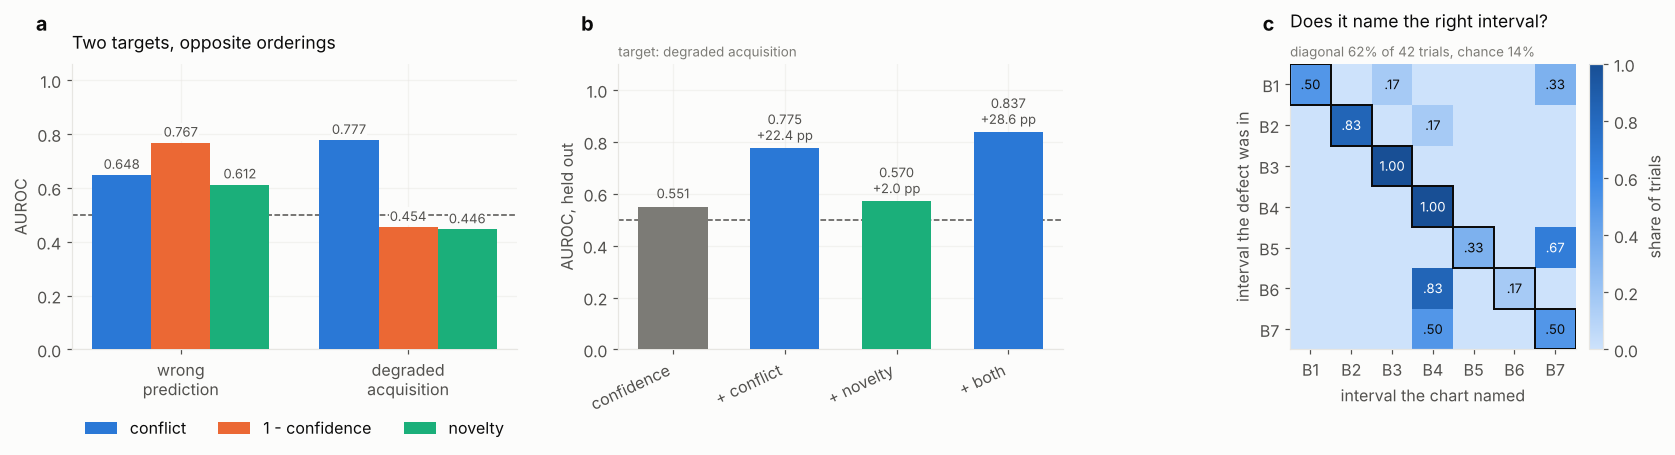

In [18]:
# --- Figure 2: what the audit adds -----------------------------------------
FIGCOL = {"conflict": CAT[0], "1 - confidence": CAT[1], "novelty": CAT[2]}
fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.5))

# (a) the same three scores against two different targets
ax = axes[0]
x, w = np.arange(2), 0.26
for j, s in enumerate(["conflict", "1 - confidence", "novelty"]):
    vals = [sep_i.loc[s, "auroc_wrong"], sep_i.loc[s, "auroc_defect"]]
    bars = ax.bar(x + (j - 1) * w, vals, w, color=FIGCOL[s], label=s, zorder=3)
    # a white box behind each label: the bars that matter here sit just under the
    # chance line, so an unmasked label is printed straight through it
    ax.bar_label(bars, fmt="%.3f", fontsize=8.6, padding=2, color=SECOND, zorder=5,
                 bbox=dict(facecolor=SURF, edgecolor="none", pad=0.8))
ax.axhline(0.5, ls="--", lw=1, color=SECOND, zorder=2)
ax.set_xticks(x, ["wrong\nprediction", "degraded\nacquisition"])
ax.set_ylim(0, 1.06)
ax.set_ylabel("AUROC")
panel(ax, "a", "Two targets, opposite orderings")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.19), ncol=3, frameon=False)

# (b) what conflict adds to the model's own posterior, out of sample
ax = axes[1]
inc = INC["degraded acquisition"].reset_index(drop=True)
for i, r in inc.iterrows():
    col = MUTED if i == 0 else (CAT[2] if r["model"] == "+ novelty" else CAT[0])
    ax.bar(i, r["auroc_heldout"], 0.62, color=col, zorder=3)
    tag = f"{r['auroc_heldout']:.3f}" + ("" if i == 0 else f"\n{r['gain_pp']:+.1f} pp")
    ax.text(i, r["auroc_heldout"] + 0.02, tag, ha="center", va="bottom",
            fontsize=8.6, color=SECOND)
ax.axhline(0.5, ls="--", lw=1, color=SECOND, zorder=2)
ax.set_xticks(np.arange(len(inc)), inc["model"], rotation=25, ha="right")
ax.set_ylim(0, 1.10)
ax.set_ylabel("AUROC, held out")
panel(ax, "b", "", "target: degraded acquisition")

# (c) asked which interval moved, does the chart name the planted one?
ax = axes[2]
M = conf_mat.div(conf_mat.sum(axis=1), axis=0).to_numpy()
im = ax.imshow(M, cmap=CSEQ, vmin=0, vmax=1)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M[i, j] > 0:
            ax.text(j, i, f"{M[i, j]:.2f}".lstrip("0"), ha="center", va="center",
                    fontsize=8.6, color="white" if M[i, j] > 0.6 else INK)
    ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False,
                               edgecolor=INK, lw=1.3, zorder=4))
ax.set_xticks(range(len(LAB)), LAB)
ax.set_yticks(range(len(LAB)), LAB)
ax.set_xlabel("interval the chart named")
ax.set_ylabel("interval the defect was in")
panel(ax, "c", "Does it name the right interval?",
      f"diagonal {hit_rate:.0%} of {len(loc)} trials, chance {1 / N_BANDS:.0%}")
ax.grid(False)
fig.colorbar(im, ax=ax, label="share of trials", fraction=0.046, pad=0.03)

fig.tight_layout()
save_pub(fig, "softwarex_figure_2_evidence")

## 8 · Everything written to disk

One CSV per manuscript object, plus the claims table, so that the text and the figures are
provably one run.

In [19]:
OUT.mkdir(parents=True, exist_ok=True)
claims.to_csv(OUT / "claims_softwarex.csv", index=False)
sep.to_csv(OUT / "softwarex_fig2a_separation.csv", index=False)
by_kind.to_csv(OUT / "softwarex_table1_by_defect.csv", index=False)
piv_kind.to_csv(OUT / "softwarex_table1_pivot.csv")
INC["degraded acquisition"].to_csv(OUT / "softwarex_fig2b_increment.csv", index=False)
conf_mat.to_csv(OUT / "softwarex_fig2c_localisation.csv")
pd.DataFrame([{"label": lab, "cm_lo": lo, "cm_hi": hi}
              for lab, (lo, hi) in zip(LAB, EDGES)]).to_csv(
    OUT / "softwarex_fig1b_bands.csv", index=False)
pd.DataFrame([{"key": k, "value": v["value"], "note": v["note"]}
              for k, v in RESULTS.items()]).to_csv(
    OUT / "softwarex_results.csv", index=False)
(OUT / "softwarex_results.json").write_text(json.dumps(RESULTS, indent=2, default=str))
print(f"wrote {len(list(OUT.glob('softwarex_*')))} files plus claims_softwarex.csv to {OUT}")

wrote 12 files plus claims_softwarex.csv to figures_quality


## What this notebook does not cover

Deliberately excluded, because the manuscript does not report them. All of it lives in
`bacteria_quality.ipynb` and is the material for the follow-up paper on the laboratory
procedure:

- the severity ladder and the pooled-batch scale ladder
- the configuration search over bands, topology, regime and preprocessing
- the comparison of five base estimators, and the accuracy versus auditability trade
- the descriptor geometry (DG, DG_early, REDG, eREDG) and the activity threshold
- the batch-level monitor comparison, false-alarm rates and reference-size requirements
- the triage policy outcomes
- preprocessing and acquisition-window pricing
- the minority-evidence record from the H1 gate
- Figure S1, the reconstruction of the documented 2018 → 2019 instrument change

The revision's additional analyses each have their own notebook in `benchmarks/`:

- `parameter_guide.ipynb`: §2.3, `docs/parameter_selection_guide.md`, and the five-split spread quoted in §3.2
- `bench_runtime.ipynb`: the runtime and memory figures in §2.2
- `short_exposure.ipynb`: the short-exposure analysis in §3.2

The test figures come from the package's own CI.

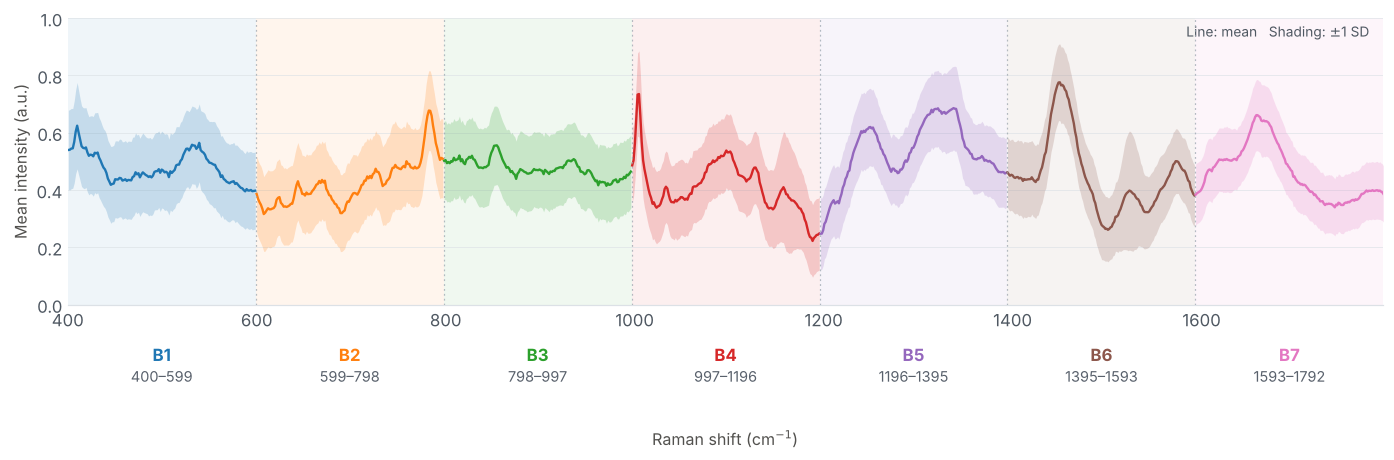

In [20]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["pdf.fonttype"] = 42  # Embed TrueType fonts

COLORS = [
    "#1f77b4",  # B1 blue
    "#ff7f0e",  # B2 orange
    "#2ca02c",  # B3 green
    "#d62728",  # B4 red
    "#9467bd",  # B5 purple
    "#8c564b",  # B6 brown
    "#e377c2",  # B7 pink
]

def save_pub(fig, name):
    OUT.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUT / f"{name}.png", dpi=600,
                bbox_inches="tight", facecolor="white")
    fig.savefig(OUT / f"{name}.pdf",
                bbox_inches="tight", facecolor="white")
    plt.show()

x = np.asarray(axis)
mu = MM_all.mean(axis=0)
sd = MM_all.std(axis=0)

fig, ax = plt.subplots(figsize=(13.0, 4.2), facecolor="white")
ax.set_facecolor("white")

for j, (lo, hi) in enumerate(EDGES):
    color = COLORS[j]
    mid = (lo + hi) / 2
    mask = (x >= lo) & (x <= hi)

    ax.axvspan(lo, hi, color=color, alpha=0.07, lw=0, zorder=0)
    ax.fill_between(
        x[mask], (mu - sd)[mask], (mu + sd)[mask],
        color=color, alpha=0.20, lw=0, zorder=2
    )
    ax.plot(x[mask], mu[mask], color=color, lw=1.55, zorder=3)

    # x is in data coordinates; y is relative to the axes.
    transform = ax.get_xaxis_transform()
    ax.text(mid, -0.14, LAB[j], transform=transform,
            ha="center", va="top", color=color,
            fontsize=11, fontweight="bold", clip_on=False)
    ax.text(mid, -0.22, f"{lo:.0f}–{hi:.0f}",
            transform=transform, ha="center", va="top",
            color="#59616c", fontsize=9.5, clip_on=False)

# Subtle dotted boundaries between bands.
for lo, _ in EDGES[1:]:
    ax.axvline(lo, color="#9ba5af", ls=(0, (1.5, 2.5)),
               lw=0.8, alpha=0.75, zorder=4)

ax.set_xlim(EDGES[0][0], EDGES[-1][1])
ax.set_ylim(0, 1.0)
ax.set_xticks(np.arange(400, 1800, 200))
ax.set_ylabel("Mean intensity (a.u.)")
ax.set_xlabel(r"Raman shift (cm$^{-1}$)", labelpad=65)

ax.yaxis.grid(True, color="#dce1e6", lw=0.65, alpha=0.65)
ax.tick_params(axis="both", length=0, colors="#4f5862", labelsize=11)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#dce1e6")

ax.text(0.99, 0.98, r"Line: mean   Shading: $\pm$1 SD",
        transform=ax.transAxes, ha="right", va="top",
        fontsize=9, color="#4f5862")

# Reserve space for the two rows of band labels and the x-axis title.
fig.subplots_adjust(left=0.07, right=0.99, top=0.96, bottom=0.34)
save_pub(fig, "softwarex_figure_1b_bands")

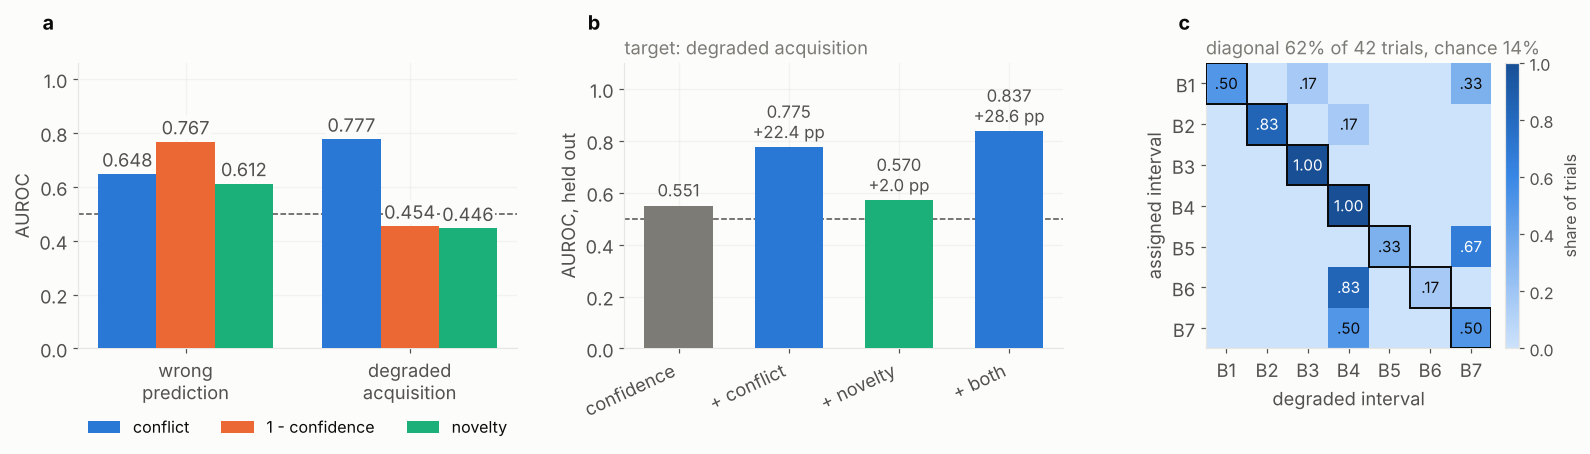

In [21]:
# --- Figure 2: what the audit adds -----------------------------------------
FIGCOL = {
    "conflict": CAT[0],
    "1 - confidence": CAT[1],
    "novelty": CAT[2],
}

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.5))

# (a) The same three scores against two different targets
ax = axes[0]
x, w = np.arange(2), 0.26

for j, s in enumerate(["conflict", "1 - confidence", "novelty"]):
    vals = [
        sep_i.loc[s, "auroc_wrong"],
        sep_i.loc[s, "auroc_defect"],
    ]
    bars = ax.bar(
        x + (j - 1) * w, vals, w,
        color=FIGCOL[s], label=s, zorder=3,
    )
    ax.bar_label(
        bars, fmt="%.3f", fontsize=12, padding=2,
        color=SECOND, zorder=5,
        bbox=dict(facecolor=SURF, edgecolor="none", pad=0.8),
    )

ax.axhline(0.5, ls="--", lw=1, color=SECOND, zorder=2)
ax.set_xticks(x, ["wrong\nprediction", "degraded\nacquisition"])
ax.set_ylim(0, 1.06)
ax.set_ylabel("AUROC")
panel(ax, "a", "")

# Keep the score names and their colors beneath panel A
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.19),
    ncol=3,
    frameon=False,
)

# (b) What conflict adds to the model's own posterior, out of sample
ax = axes[1]
inc = INC["degraded acquisition"].reset_index(drop=True)

for i, r in inc.iterrows():
    col = MUTED if i == 0 else (
        CAT[2] if r["model"] == "+ novelty" else CAT[0]
    )
    ax.bar(i, r["auroc_heldout"], 0.62, color=col, zorder=3)

    tag = f"{r['auroc_heldout']:.3f}"
    if i != 0:
        tag += f"\n{r['gain_pp']:+.1f} pp"

    ax.text(
        i, r["auroc_heldout"] + 0.02, tag,
        ha="center", va="bottom",
        fontsize=11, color=SECOND,
    )

ax.axhline(0.5, ls="--", lw=1, color=SECOND, zorder=2)
ax.set_xticks(
    np.arange(len(inc)),
    inc["model"],
    rotation=25,
    ha="right",
)
ax.set_ylim(0, 1.10)
ax.set_ylabel("AUROC, held out")
panel(
    ax, "b", "",
    "target: degraded acquisition",
)
for text in ax.texts:
    if text.get_text() == "target: degraded acquisition":
        text.set_fontsize(12)
# (c) Does the audit identify the interval containing the planted defect?
ax = axes[2]
M = conf_mat.div(conf_mat.sum(axis=1), axis=0).to_numpy()
im = ax.imshow(M, cmap=CSEQ, vmin=0, vmax=1)

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M[i, j] > 0:
            ax.text(
                j, i, f"{M[i, j]:.2f}".lstrip("0"),
                ha="center", va="center", fontsize=10,
                color="white" if M[i, j] > 0.6 else INK,
            )

    ax.add_patch(
        plt.Rectangle(
            (i - 0.5, i - 0.5), 1, 1,
            fill=False, edgecolor=INK, lw=1.3, zorder=4,
        )
    )

ax.set_xticks(range(len(LAB)), LAB)
ax.set_yticks(range(len(LAB)), LAB)
ax.set_xlabel("degraded interval")
ax.set_ylabel("assigned interval")
panel(
    ax, "c", "",
    f"diagonal {hit_rate:.0%} of {len(loc)} trials, "
    f"chance {1 / N_BANDS:.0%}",
)
for text in ax.texts:
    if text.get_text().startswith("diagonal "):
        text.set_fontsize(12)
ax.grid(False)

cb = fig.colorbar(
    im, ax=ax, label="share of trials",
    fraction=0.046, pad=0.03,
)

for ax in axes:
    ax.xaxis.label.set_fontsize(12)  # Axis titles
    ax.yaxis.label.set_fontsize(12)
    ax.tick_params(axis="both", labelsize=12)  # Tick labels
    
# First complete the automatic layout; then shift C and its colorbar.
fig.tight_layout()
fig.canvas.draw()

shift = 0.05  # Fraction of figure width; increase slightly if needed
for moving_ax in (axes[2], cb.ax):
    p = moving_ax.get_position()
    moving_ax.set_position([p.x0 - shift, p.y0, p.width, p.height])

save_pub(fig, "softwarex_figure_2_evidence")